# Test notebook for PlantCV-Geospatial RGB tutorial

This is a version of the RGB tutorial notebook with everything that cannot be tested, such as steps requiring napari, removed. 

## 1. Imports
Select your PlantCV environment and then import the libaries

In [1]:
# Set the notebook display method.
%matplotlib widget

import plantcv.plantcv as pcv
import plantcv.geospatial as gcv

pcv.params.debug = "plot"
pcv.params.sample_label = "rgb_tutorial"

# Change text size parameters
pcv.params.text_size = 25
pcv.params.text_thickness = 20

## 2. Read GeoTIFF RGB Image and make field and plot boundaries in Napari

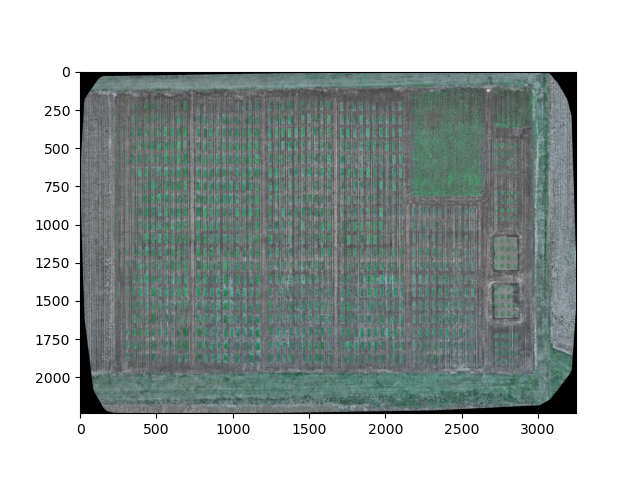

In [2]:
# Read GeoTIFF with PlantCV-Geospatial
img = gcv.read.geotif(
    filename="./img/South-Block-Color-Ortho-11-22-2024-orthophoto.tif", 
    bands="R,G,B"
    )



#### Make the field boundary in Napari


In [3]:
# This cell opens a Napari window, where you can create layers.
# Run this cell, then draw the field boundary in the field_boundary layer in Napari.
# For this field, we will zoom in on only one of the 10 x 20 blocks
# There are 4 blocks starting on the left side, choose one to draw a shape around
# Leave some space on the outer edge of your field, approximately half the space between each plot
# In Napari, select field_boundary, choose the polygon tool, and draw the field outline, then press enter.
# *Note* keep the napari viewer open!

#editor = gcv.create_shapes.InteractiveShapes(
#    img=img,
#    viewer_type="napari",
#    field_layer="field_boundary",
#    show=True,
#    )


#### Save the Field Boundary as GeoJSON


In [6]:
# Save the field boundary layer as a georeferenced GeoJSON.
# This boundary file can be reused later to crop/reload the GeoTIFF.
#editor.to_shapes(
#    dest="./shape_files/rgb_tutorial_field_boundaries.geojson",
#    layername="field_boundary",
#    shapetype="polygon",
#)


[[(271.7284240722656, 163.69110107421875),
  (718.4955444335938, 163.69110107421875),
  (718.4955444335938, 1924.13232421875),
  (271.7284240722656, 1924.13232421875)]]

#### Define Plot Boundaries


In [7]:
# Split the field boundary into plot-grid lines.
# numdivs = [number of columns, number of ranges]
#editor.grid(numdivs=[10, 20])


In [8]:
# After adjusting grid lines in Napari, convert the grid lines into plot polygons.
# Adjust the shape or delete individual polygons in the Plots layer in Napari after if needed.
#editor.plots(plot_layer="Plots")

In [9]:
# Save the plot polygon layer as a georeferenced GeoJSON.
#editor.to_shapes(
#    dest="./shape_files/rgb_tutorial_plot_boundaries.geojson", 
#    layername="Plots", 
#    shapetype="polygon"
#    )

# Close your editor
#editor.close()

## 3. Or skip Step2 and Load an Existing Plot GeoJSON

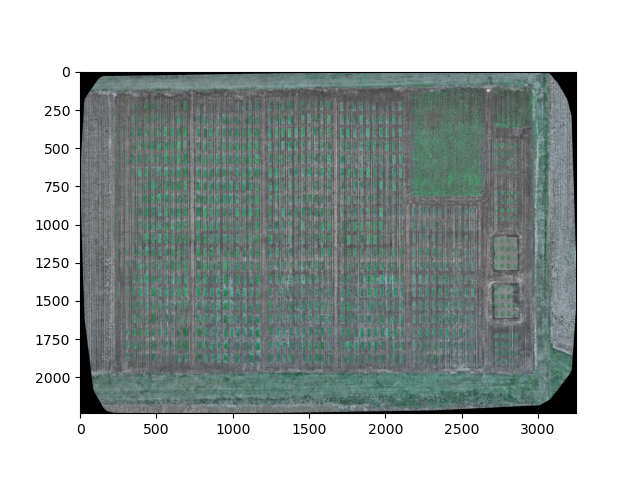

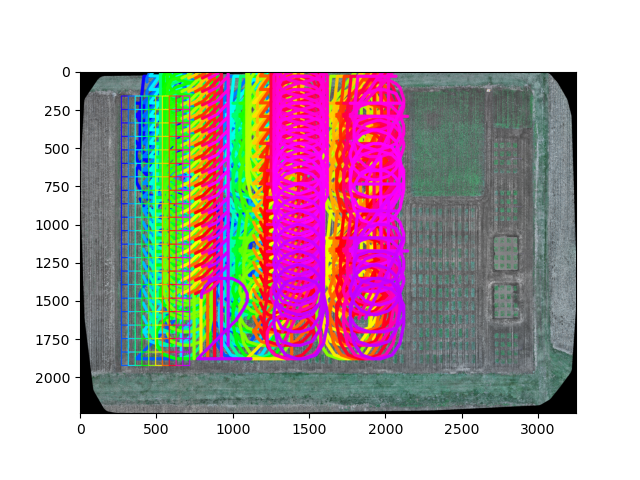

In [10]:
# Read GeoTIFF with PlantCV-Geospatial
img = gcv.read.geotif(
    filename="./img/South-Block-Color-Ortho-11-22-2024-orthophoto.tif", 
    bands="R,G,B"
    )

# Use this to load in the plot map if it already exists.
plot_rois = gcv.convert.to_roi(
    img=img, 
    geojson="./shape_files/rgb_tutorial_plot_boundaries.geojson"
    )


## 4. Explore RGB indicies & Colorspaces for assessing canopy coverage

/Users/MarcusGriffiths/Github/plantcv/plantcv/plantcv/plantcv/transform/rescale.py:30: RuntimeWarning: invalid value encountered in cast
  rescaled_img = (rescaled_img).astype('uint8')


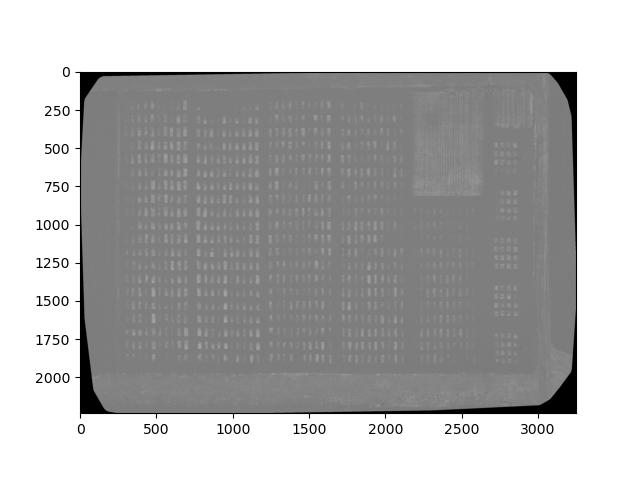

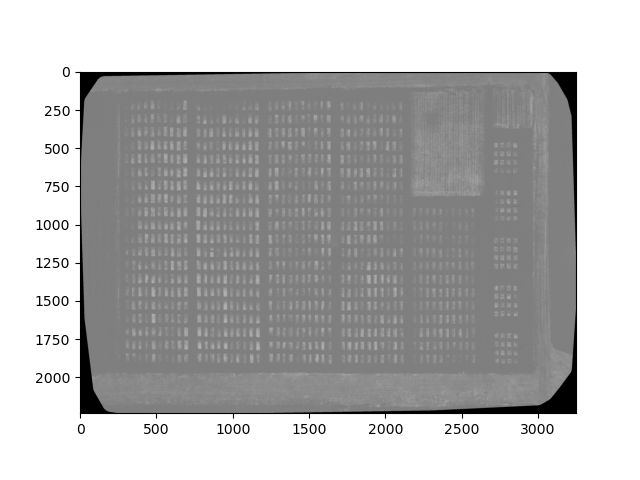

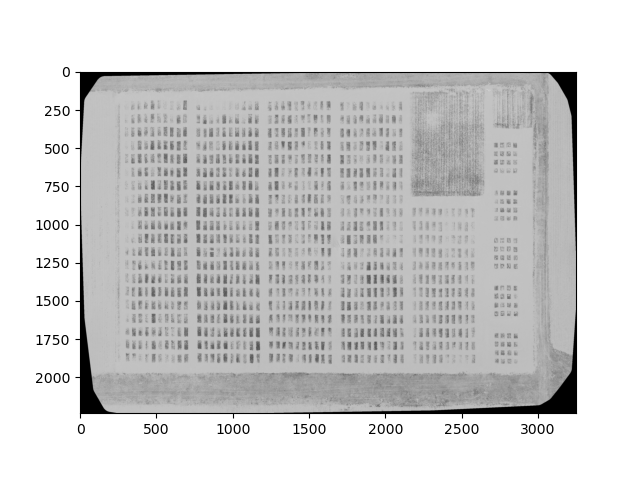

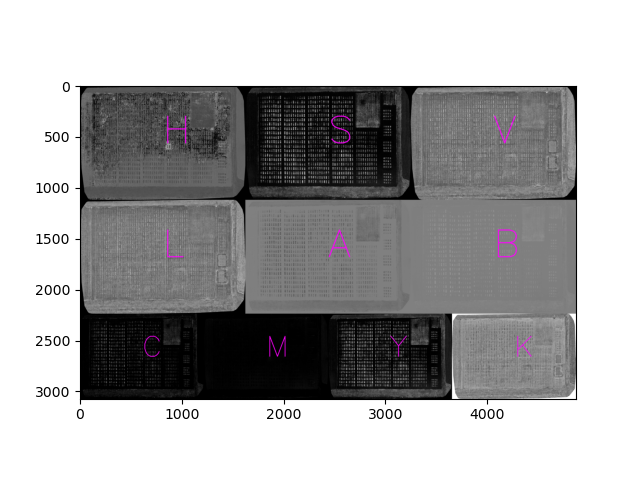

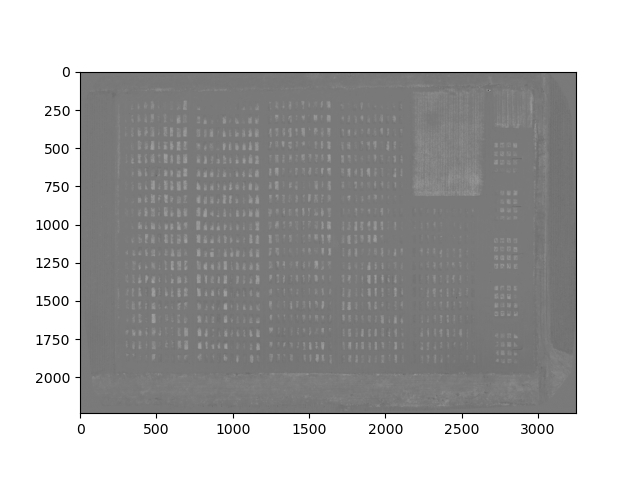

In [11]:
# Visualize RGB indices and colorspaces from the GeoTIFF thumbnail.
# The goal is to find one where your plants stand out from the background

# blue-green index, green leaf index, and soil color index are often useful:
bgi = pcv.spectral_index.bgi(img.thumb)
gli = pcv.spectral_index.gli(img.thumb)
sci = pcv.spectral_index.sci(img.thumb)

# View all colorspaces
colorspace_img = pcv.visualize.colorspaces(rgb_img=img.thumb, original_img=False)

# Look at the blue-yellow colorspace in grayscale
b_channel = pcv.rgb2gray_lab(rgb_img=img.thumb, channel="b")


## 5. Threshold & create a canopy mask using the chosen index (BGI)

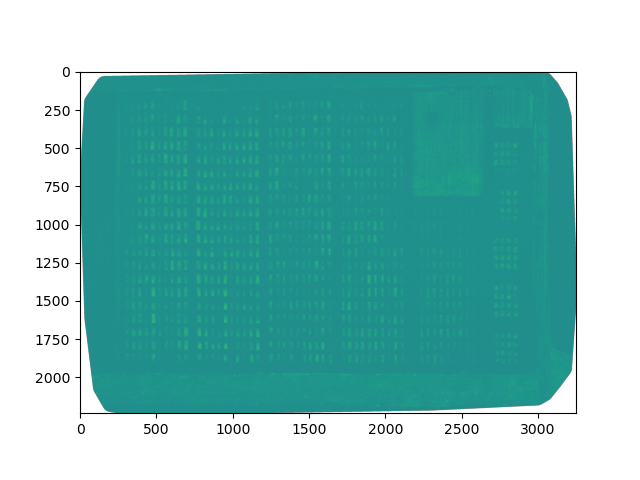

alt.Chart(...)

In [12]:
pcv.plot_image(bgi.array_data, cmap="viridis")
_ = pcv.visualize.histogram(img=bgi.array_data, bins=60)

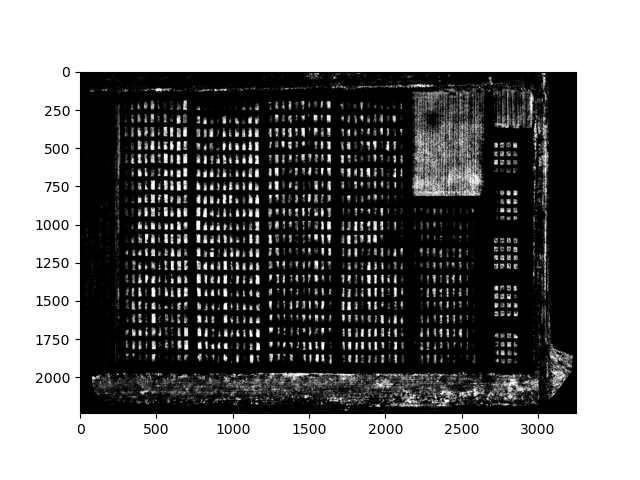

In [13]:
# Adjust this threshold after looking at the BGI image and histogram.
plant_mask = pcv.threshold.binary(
    gray_img=bgi.array_data,
    threshold=0.06,
    object_type="light",
)

## 6. Measure Percent Coverage from plant mask


/Users/MarcusGriffiths/miniforge3/envs/plantcv/lib/python3.12/site-packages/rasterstats/io.py:335: NodataWarning: Setting nodata to -999; specify nodata explicitly
  warnings.warn(


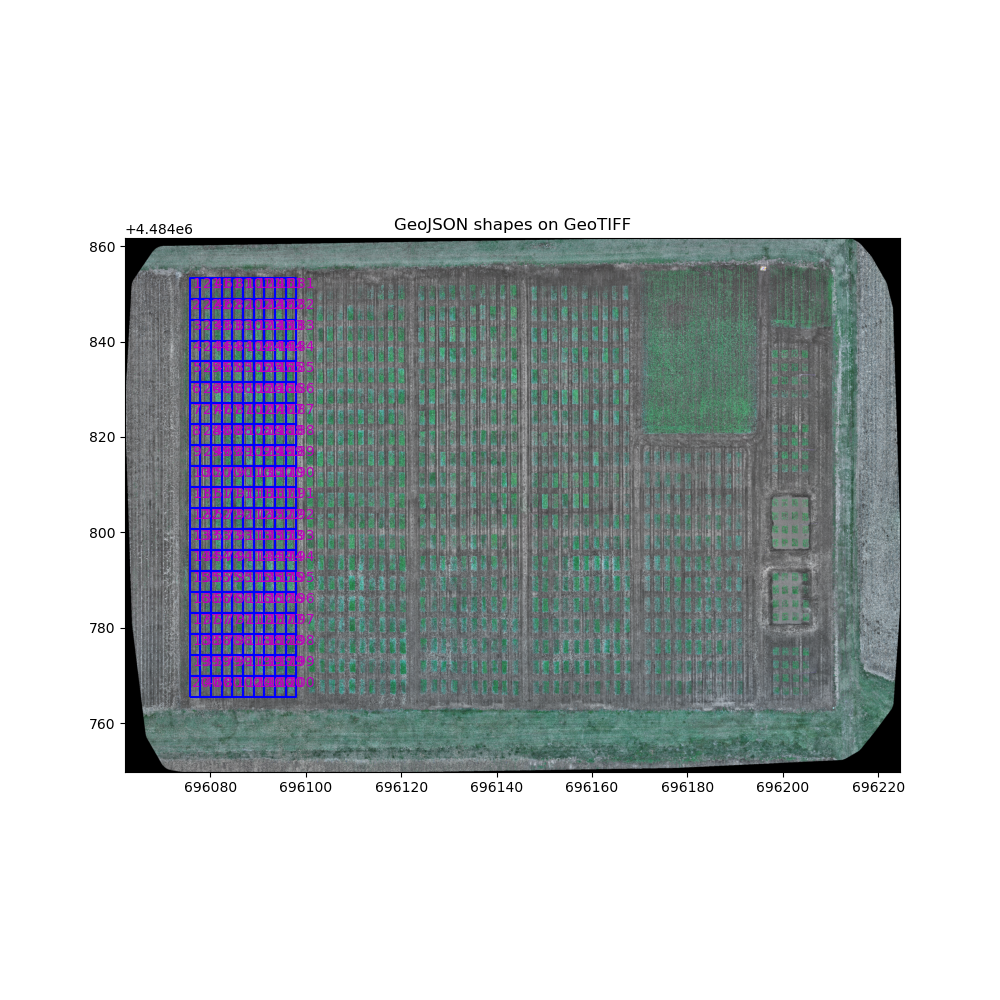

In [14]:
# Analyze plot-level percent coverage.
# Requires a GeoTIFF image and a plot GeoJSON.
coverage = gcv.analyze.coverage(
    img=img,
    bin_mask=plant_mask,
    geojson="./shape_files/rgb_tutorial_plot_boundaries.geojson",
    label="coverage",
)


#### *Optional.* View the percent coverage results


In [15]:
from IPython.display import HTML

# Keep only plot number and percent coverage.
coverage_rows = []

for sample, obs in pcv.outputs.observations.items():
    plot_number = sample.split("_")[-1]
    percent_coverage = obs["percent_coverage"]["value"] * 100
    coverage_rows.append([plot_number, round(percent_coverage, 2)])

coverage_rows.sort(key=lambda row: int(row[0]))

html = "<table><tr><th>plot_number</th><th>percent_coverage</th></tr>"
for plot_number, percent_coverage in coverage_rows:
    html += f"<tr><td>{plot_number}</td><td>{percent_coverage}</td></tr>"
html += "</table>"

display(HTML(html))

plot_number,percent_coverage
1,0.75
2,1.81
3,6.3
4,0.8
5,5.48
6,1.06
7,3.25
8,2.27
9,4.52
10,0.52


#### Save the percent coverage results


In [16]:
# Save the full PlantCV outputs file.
pcv.outputs.save_results(filename="./rgb_tutorial_results.csv", outformat="csv")

# Optional: Make rows within plots to exclude edge effects

In [3]:
# This time create a field_bounday layer with no space around the outer edges
#editor = gcv.create_shapes.InteractiveShapes(
#    img=img,
#    viewer_type="napari",
#    field_layer="field_boundary",
#    show=True,
#    )

#editor.add_layer(layer_type="points", layername="field_points")

In [4]:
# Save as a new shapefile
#editor.to_points(
#    dest="./shape_files/rgb_tutorial_close_crop.geojson",
#   layername="field_points"
#)

[(288.6231009248619, 191.76681067066426),
 (702.5923197674064, 186.4803668151111),
 (711.4536607388723, 1910.5418264768837),
 (296.2310965456517, 1904.8382198258741)]

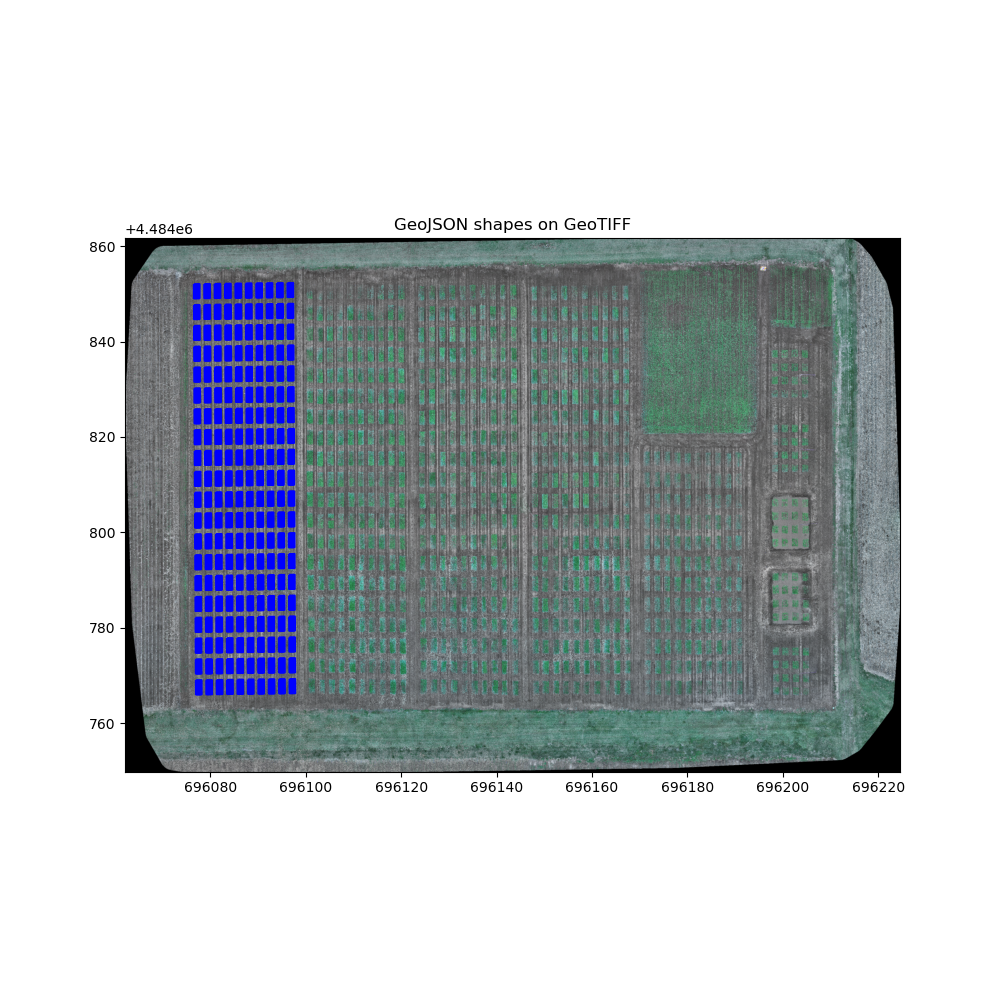

In [8]:
# The precision of your planting will determine how perfectly an automatic grid will line up
# Adjust length and spacing parameters until you capture your plots well enough 

#indiv_rows = gcv.create_shapes.auto_grid(img=img, field_corners_path="./shape_files/rgb_tutorial_close_crop.geojson", 
#            out_path="./rgb_tutorial_auto_grid.geojson", num_ranges=20, num_columns=10,
#            num_rows=7, range_spacing=1.42, range_length=2.95, row_length=0.17, column_spacing=0.99)

# These plot boundaries can be saved and the analysis of coverage run on each row individually
# Then, in analyzing the data, you can remove outer rows to eliminate edge effects
# Alternatively, you can adjust your plot boundaries and spacing to not include edge rows in the plots at all